Dati filtrati:
[[16.1496 19.8   ]
 [16.452  19.9   ]
 [16.4952 19.6   ]
 [17.6148 20.7   ]
 [17.7228 20.4   ]
 [13.5432 16.9   ]
 [12.7368 16.3   ]
 [ 6.9984  7.9   ]
 [11.4372 13.9   ]
 [11.5704 14.6   ]
 [14.7816 17.4   ]
 [16.2432 19.9   ]
 [23.6556 24.2   ]
 [23.2632 22.6   ]
 [25.4592 32.    ]
 [19.0368 16.3   ]
 [18.5616 16.5   ]
 [12.4236 10.5   ]
 [10.836   9.3   ]
 [ 8.0064  6.6   ]
 [ 8.5068  7.4   ]
 [19.7316 23.6   ]
 [14.364  21.3   ]
 [ 7.308   8.6   ]
 [ 6.8616  8.4   ]
 [ 7.2828  8.3   ]
 [ 7.182   7.9   ]
 [ 7.3728  7.7   ]
 [ 8.2944  8.8   ]
 [17.9496 22.    ]
 [20.6424 26.7   ]
 [25.686  23.8   ]
 [19.1592 25.3   ]
 [18.6624 24.2   ]
 [13.6404 16.9   ]
 [13.6584 16.9   ]
 [13.4856 17.4   ]
 [ 8.6184  9.2   ]
 [ 8.3232  9.2   ]
 [ 7.9596  8.6   ]
 [ 7.5024  4.8   ]
 [ 7.29    7.9   ]
 [ 7.4484  8.    ]
 [ 6.6888  7.    ]
 [21.8916 27.5   ]
 [22.7988 30.1   ]
 [17.4276 22.1   ]
 [ 7.2792  6.5   ]
 [ 7.8804  6.4   ]
 [ 7.6608  7.    ]
 [ 9.2628  8.1   ]
 [10.3932  8.1  

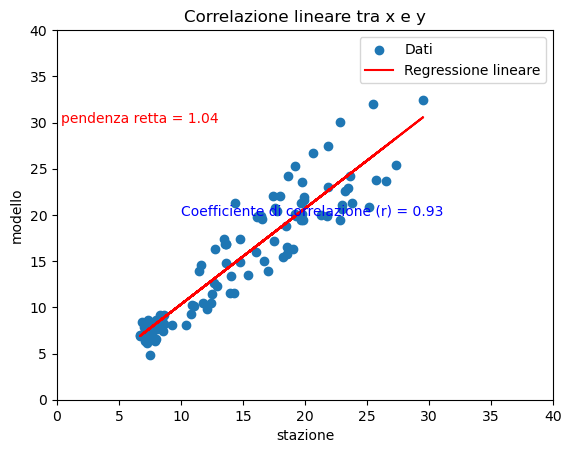

In [13]:
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
# Connessione al database SQLite
conn = sqlite3.connect(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\nuvole.db')
cursor = conn.cursor()

# Query per selezionare i dati dalle colonne desiderate della tabella
query_dati = "SELECT modello, stazione FROM st119clearsky WHERE modello IS NOT NULL AND modello != 'NULL' AND stazione IS NOT NULL AND stazione != 'NULL'"
cursor.execute(query_dati)
filtered_rows = cursor.fetchall()

# Chiusura della connessione al database
conn.close()

# Filtraggio dei dati nelle righe ottenute
filtered_data = [(float(row[0]), float(row[1])) for row in filtered_rows]

# Converti i dati in array NumPy
filtered_data = np.array(filtered_data)

# Estrai x e y dai dati filtrati
x = filtered_data[:, 0]
y = filtered_data[:, 1]

# Stampa dei dati filtrati
print("Dati filtrati:")
print(filtered_data)


# Calcolo della retta di regressione lineare
slope, intercept = np.polyfit(x, y, 1)
line = slope * x + intercept

# Calcolo del coefficiente di correlazione lineare (r)
r = np.corrcoef(x, y)[0, 1]

# Creazione del grafico
plt.scatter(x, y, label='Dati')
plt.plot(x, line, color='red', label='Regressione lineare')

# Aggiunta del coefficiente di correlazione lineare (r) come testo nel grafico
plt.text(10, 20, f'Coefficiente di correlazione (r) = {r:.2f}', fontsize=10, color='blue')
plt.text(0.3, 30, f'pendenza retta = {slope:.2f}', fontsize=10, color='red')

# Aggiunta di titoli e legenda
plt.title('Correlazione lineare tra x e y')
plt.xlabel('stazione')
plt.ylabel('modello')
plt.legend()
plt.xlim(0,40)
plt.ylim(0,40)
# Mostra il grafico
plt.show()